<a href="https://colab.research.google.com/github/samragyk-123/Python-II-Final-Project/blob/main/notebooks/china_health_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

url = "https://raw.githubusercontent.com/samragyk-123/Python-II-Final-Project/refs/heads/main/data/raw/china_health_raw.xlsx%20-%20Sheet1.csv"
df = pd.read_csv(url)
df.head()

,Year,Province,"Health Personnel (per 1,000 population)","Hospital Beds (per 1,000 population)",Health Care Institutions (count),Number of Visits (100 million),"Patients Discharged (10,000 person-times)",Hospital Bed Utilization Rate (%)
0,2011,Beijing,23.57,9.47,9495,1.62,201.18,84.4
1,2012,Beijing,25.32,10.02,9632,1.85,224.92,84.3
2,2013,Beijing,26.31,10.40,9683,2.05,245.62,83.5
3,2014,Beijing,27.40,10.98,9638,2.14,269.30,83.2
4,2015,Beijing,28.92,11.16,9771,2.18,275.40,80.6


In [2]:
df = pd.read_csv(url)

df.columns = ["Year","Province","staff","beds","institutions",
              "visits","discharges","bed_util"]

df["Province"] = df["Province"].replace({"Shangai":"Shanghai", "Guandong":"Guangdong"})

# drop 2024 completely
df = df[df["Year"] <= 2023].copy()

print(df.shape)           # should be (403, 8)
print(df.isna().sum())


(403, 8)
Year            0
Province        0
staff           0
beds            0
institutions    0
visits          0
discharges      0
bed_util        0
dtype: int64


In [3]:
pop = pd.read_csv("https://raw.githubusercontent.com/samragyk-123/Python-II-Final-Project/refs/heads/main/data/raw/China%20province%20population%20-%20Sheet1.csv")

# rename to match the code later
pop = pop.rename(columns={"Population": "pop_10k"})

# clean up possible gotchas
pop["Province"] = pop["Province"].str.strip()        # removes hidden spaces
pop = pop[pop["Year"] <= 2023]                        # drop 2024 if it's in there

df = df.merge(pop[["Province","Year","pop_10k"]], on=["Province","Year"], how="left")

print(df["pop_10k"].isna().sum())   # MUST be 0
print(df.shape)                     # should still be (403, 9)

0
(403, 9)


In [4]:
df["beds_pc"]      = df["beds"]       / df["pop_10k"] * 1000   # beds per 1,000 people
df["staff_pc"]     = df["staff"]      / df["pop_10k"] * 1000   # health personnel per 1,000
df["discharge_pc"] = df["discharges"] / df["pop_10k"] * 1000   # discharges per 1,000
df["visits_pc"]    = df["visits"] * 10000 / df["pop_10k"]       # visits per person per year

In [5]:
region_map = {}
for p in ["Beijing","Tianjin","Hebei","Shanghai","Jiangsu","Zhejiang",
          "Fujian","Shandong","Guangdong","Hainan"]: region_map[p] = "East"
for p in ["Shanxi","Anhui","Jiangxi","Henan","Hubei","Hunan"]: region_map[p] = "Central"
for p in ["Inner Mongolia","Guangxi","Chongqing","Sichuan","Guizhou","Yunnan",
          "Xizang","Shaanxi","Gansu","Qinghai","Ningxia","Xinjiang"]: region_map[p] = "West"
for p in ["Liaoning","Jilin","Heilongjiang"]: region_map[p] = "Northeast"

df["Region"] = df["Province"].map(region_map)
df["Region"].isna().sum()   # should be 0

np.int64(0)

In [6]:
#df.to_csv("china_health_clean.csv", index=False)

In [7]:
#from google.colab import files
#files.download("china_health_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
df[["beds_pc", "staff_pc", "discharge_pc", "visits_pc"]].describe().round(2)

,beds_pc,staff_pc,discharge_pc,visits_pc
count,403.00,403.00,403.00,403.00
mean,5.67,8.82,157.60,5.54
std,1.40,2.17,43.81,1.92
min,2.31,4.38,39.56,2.36
25%,4.62,7.26,125.07,4.26
50%,5.72,8.66,153.73,5.07
75%,6.72,10.10,184.13,6.25
max,8.93,19.22,324.01,13.59


In [9]:
df.sort_values("staff_pc", ascending=False)[["Province","Year","staff_pc"]].head(5)
df.sort_values("visits_pc", ascending=False)[["Province","Year","visits_pc"]].head(5)

,Province,Year,visits_pc
12,Beijing,2023,13.586957
142,Zhejiang,2023,13.518851
141,Zhejiang,2022,12.225154
140,Zhejiang,2021,11.600968
8,Beijing,2019,11.380256



########## 1) OVERALL SUMMARY, 2019 vs 2023 ##########


Year                  2019    2023
beds_pc      count   31.00   31.00
             mean     6.38    7.48
             std      0.88    0.85
             min      4.67    5.41
             25%      5.85    6.92
             50%      6.38    7.59
             75%      7.16    8.08
             max      7.82    8.93
staff_pc     count   31.00   31.00
             mean     9.67   11.71
             std      1.44    1.89
             min      7.56    8.88
             25%      9.07   10.52
             50%      9.38   11.37
             75%     10.07   12.26
             max     15.69   19.22
inst_pc      count   31.00   31.00
             mean     7.77    8.41
             std      3.44    3.46
             min      2.28    2.76
             25%      5.72    6.46
             50%      7.29    7.94
             75%      8.93    9.31
             max     21.03   22.84
discharge_pc count   31.00   31.00
             mean   184.99  216.51
             std     38.76   49.12
             min     92.33  114.47
             25%    158.38  177.82
             50%    183.21  217.56
             75%    213.95  246.83
             max    246.34  324.01
visits_pc    count   31.00   31.00
             mean     6.13    6.88
             std      2.08    2.41
             min      3.20    3.17
             25%      4.80    5.40
             50%      5.61    6.43
             75%      6.63    7.78
             max     11.38   13.59
bed_util     count   31.00   31.00
             mean    81.98   77.72
             std      6.45    7.15
             min     64.80   54.40
             25%     79.10   72.55
             50%     82.20   79.60
             75%     85.25   81.50
             max     96.20   91.00


########## 2) REGION MEANS, 2019 vs 2023 ##########


beds_pc  staff_pc  inst_pc  discharge_pc  visits_pc  bed_util
Year Region                                                                  
2019 Central       6.51      8.76     7.77        199.09       5.19     84.77
     East          5.59     10.01     5.84        163.85       8.22     83.81
     Northeast     7.06      9.08     7.39        162.57       4.01     74.83
     West          6.81      9.99     9.46        201.15       5.38     80.85
2023 Central       7.72     10.39     8.21        216.43       6.02     78.70
     East          6.83     12.56     6.83        200.47       9.24     79.18
     Northeast     7.20      9.93     7.69        169.68       3.92     71.43
     West          7.98     12.12    10.02        241.62       6.08     77.59


########## 3) REGION STD, 2019 vs 2023 ##########


beds_pc  staff_pc  inst_pc  discharge_pc  visits_pc  bed_util
Year Region                                                                  
2019 Central       0.69      0.88     2.58         37.97       1.01      5.26
     East          0.60      2.13     2.62         23.56       2.31      5.21
     Northeast     0.48      0.39     1.43          8.37       0.73      1.23
     West          0.81      0.88     4.08         45.16       0.75      7.46
2023 Central       0.66      0.54     1.91         41.37       1.06      4.95
     East          0.74      2.56     2.76         30.53       2.60      5.93
     Northeast     0.45      0.97     1.97         14.07       0.66      0.68
     West          0.77      1.19     4.33         59.02       1.07      9.27


===== beds_pc (2019) =====
Top 5:
    Province    Region  beds_pc
    Xinjiang      West     7.82
     Sichuan      West     7.71
       Hunan   Central     7.65
   Chongqing      West     7.55
Heilongjiang Northeast     7.44
Bottom 5:
 Province Region  beds_pc
Guangdong   East     4.67
  Tianjin   East     4.75
   Fujian   East     5.08
   Xizang   West     5.18
   Hainan   East     5.27

===== staff_pc (2019) =====
Top 5:
Province Region  staff_pc
 Beijing   East     15.69
  Xizang   West     11.76
 Shaanxi   West     11.33
 Qinghai   West     10.75
Zhejiang   East     10.49
Bottom 5:
    Province    Region  staff_pc
       Anhui   Central      7.56
     Jiangxi   Central      7.77
   Guangdong      East      8.24
      Fujian      East      8.39
Heilongjiang Northeast      8.66

===== inst_pc (2019) =====
Top 5:
Province  Region  inst_pc
  Xizang    West    21.03
  Shanxi Central    11.98
   Hebei    East    11.52
 Qinghai    West    11.29
   Gansu    West    10.58
Bottom 5:
 Provi

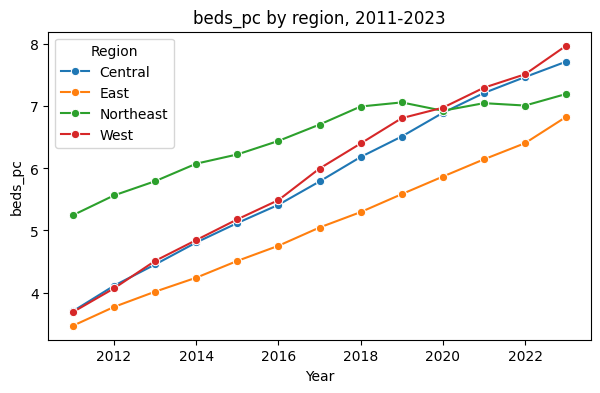

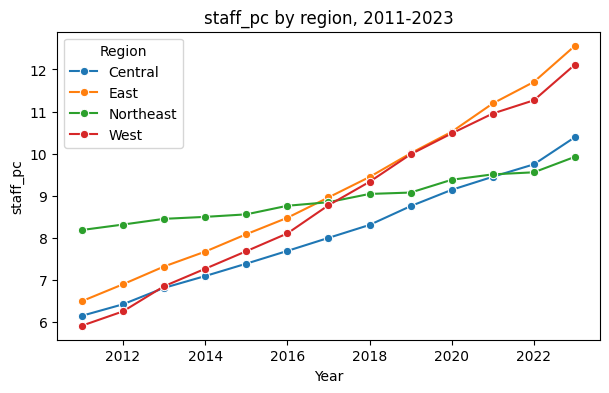

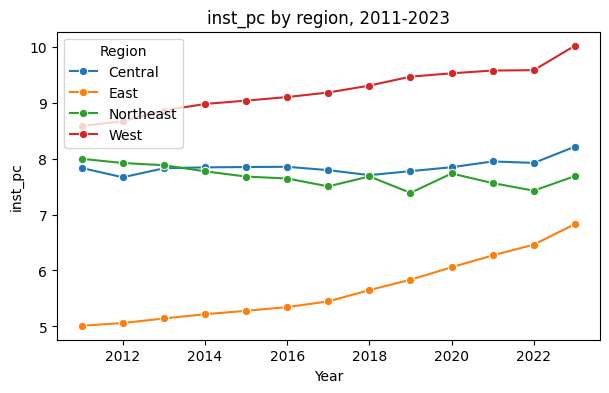

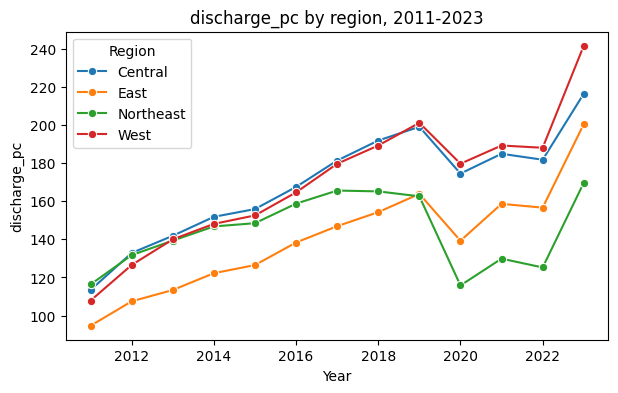

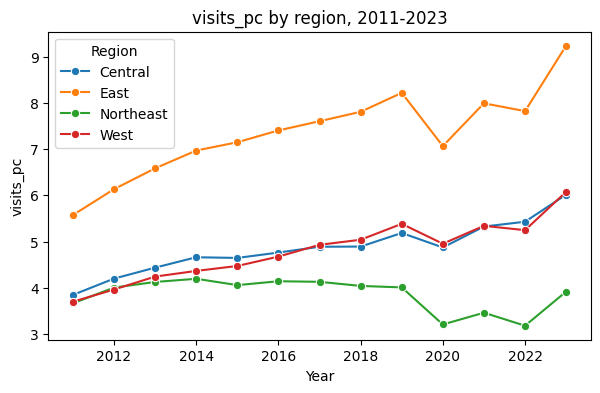

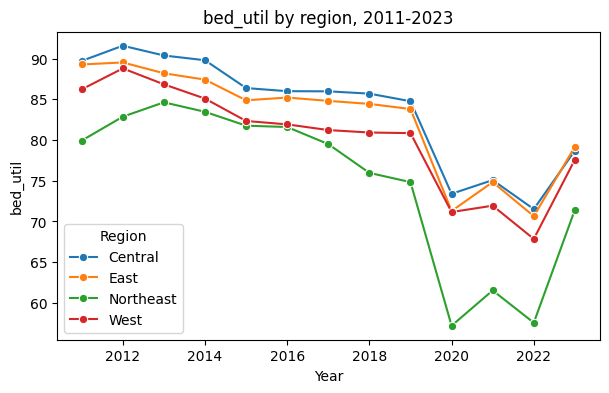

In [10]:
from IPython.display import display

# ---------- SETUP ----------
df["inst_pc"] = df["institutions"] / df["pop_10k"]   # institutions per 10,000 people
vars_ = ["beds_pc", "staff_pc", "inst_pc", "discharge_pc", "visits_pc", "bed_util"]

d19 = df[df["Year"] == 2019]
d23 = df[df["Year"] == 2023]
both = df[df["Year"].isin([2019, 2023])]

# ---------- 1) OVERALL SUMMARY, 2019 vs 2023 ----------
print("\n########## 1) OVERALL SUMMARY, 2019 vs 2023 ##########")
display(both.groupby("Year")[vars_].describe().T.round(2))

# ---------- 2) BY REGION: MEANS ----------
print("\n########## 2) REGION MEANS, 2019 vs 2023 ##########")
display(both.groupby(["Year", "Region"])[vars_].mean().round(2))

# ---------- 3) BY REGION: SPREAD (STD) ----------
print("\n########## 3) REGION STD, 2019 vs 2023 ##########")
display(both.groupby(["Year", "Region"])[vars_].std().round(2))

# ---------- 4) RANKINGS (TOP 5 / BOTTOM 5), 2019 AND 2023 ----------
for yr, d in [(2019, d19), (2023, d23)]:
    for v in vars_:
        print(f"\n===== {v} ({yr}) =====")
        print("Top 5:")
        print(d.sort_values(v, ascending=False)[["Province", "Region", v]].head(5).round(2).to_string(index=False))
        print("Bottom 5:")
        print(d.sort_values(v)[["Province", "Region", v]].head(5).round(2).to_string(index=False))

# ---------- 5) TREND LINES BY REGION, 2011-2023 ----------
for v in vars_:
    g = df.groupby(["Year", "Region"])[v].mean().reset_index()
    plt.figure(figsize=(7, 4))
    sns.lineplot(data=g, x="Year", y=v, hue="Region", marker="o")
    plt.title(f"{v} by region, 2011-2023")
    plt.show()

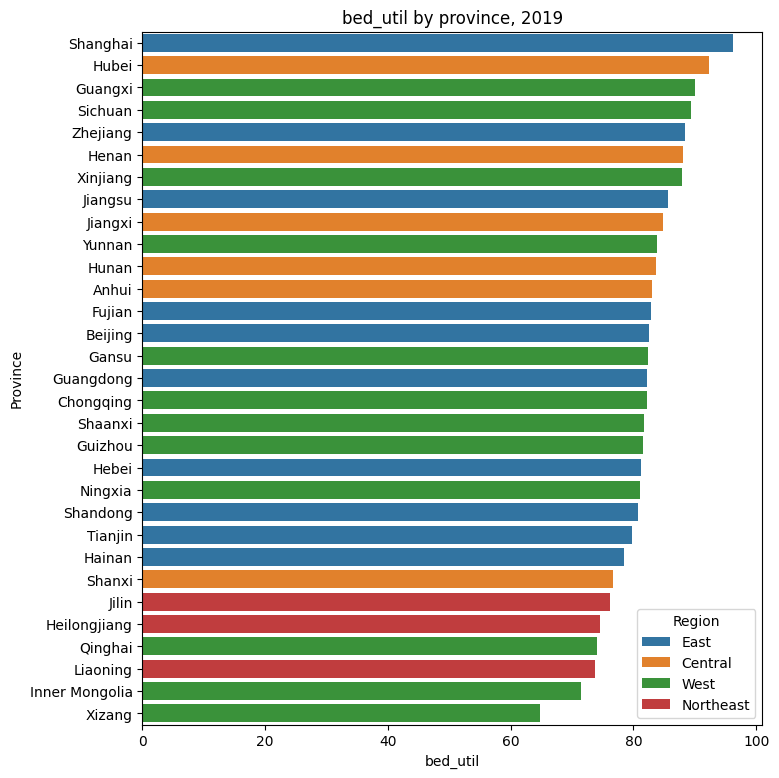

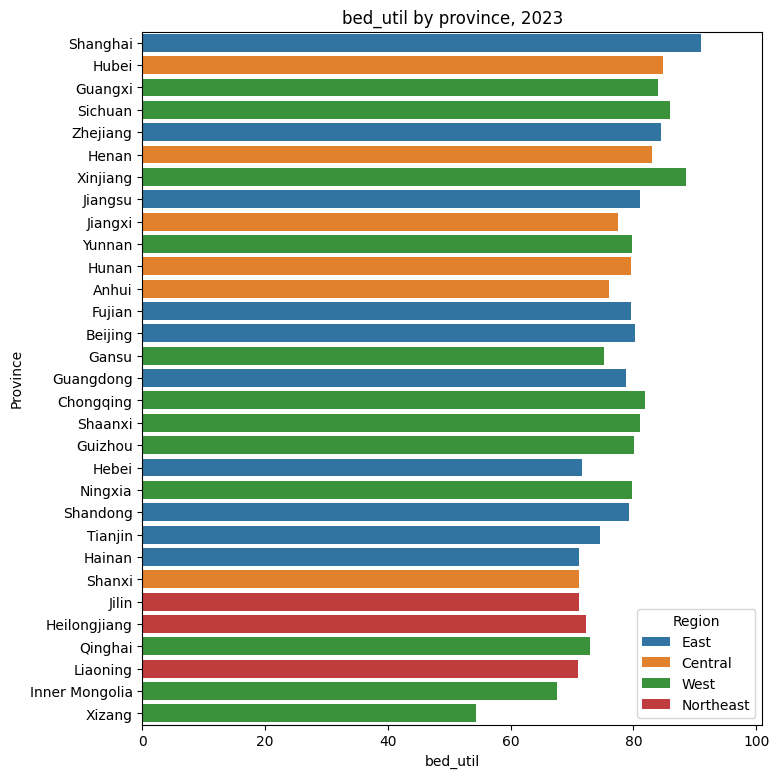

In [11]:
var = "bed_util"      # <- swap to "beds_pc" if you want beds

order = df[df["Year"]==2019].sort_values(var, ascending=False)["Province"]
xmax = df[df["Year"].isin([2019,2023])][var].max() * 1.05

for yr in [2019, 2023]:
    d = df[df["Year"]==yr]
    plt.figure(figsize=(8,9))
    sns.barplot(data=d, y="Province", x=var, order=order,
                hue="Region", dodge=False)
    plt.xlim(0, xmax)
    plt.title(f"{var} by province, {yr}")
    plt.show()

              beds_pc  staff_pc  inst_pc  discharge_pc  visits_pc  bed_util
beds_pc          1.00     -0.01     0.11          0.72      -0.42      0.09
staff_pc        -0.01      1.00     0.17         -0.11       0.44     -0.16
inst_pc          0.11      0.17     1.00         -0.25      -0.49     -0.60
discharge_pc     0.72     -0.11    -0.25          1.00      -0.04      0.64
visits_pc       -0.42      0.44    -0.49         -0.04       1.00      0.52
bed_util         0.09     -0.16    -0.60          0.64       0.52      1.00
              beds_pc  staff_pc  inst_pc  discharge_pc  visits_pc  bed_util
beds_pc          1.00      0.11     0.38          0.64      -0.46      0.03
staff_pc         0.11      1.00     0.20         -0.00       0.13     -0.18
inst_pc          0.38      0.20     1.00          0.01      -0.61     -0.40
discharge_pc     0.64     -0.00     0.01          1.00       0.06      0.66
visits_pc       -0.46      0.13    -0.61          0.06       1.00      0.51
bed_util    

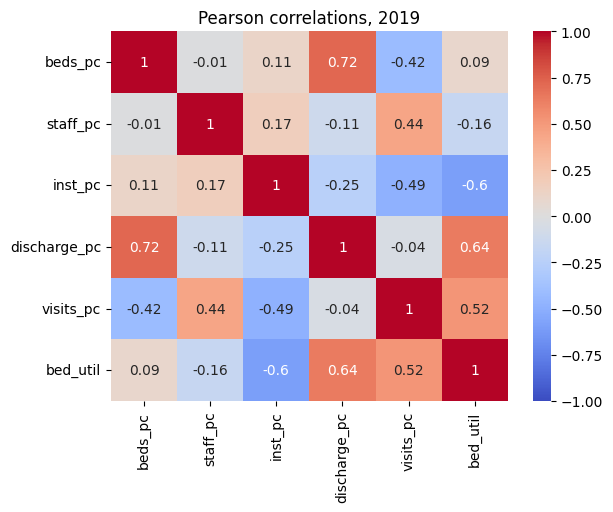

In [12]:
d19 = df[df["Year"]==2019]
cols = ["beds_pc","staff_pc","inst_pc","discharge_pc","visits_pc","bed_util"]

pearson  = d19[cols].corr(method="pearson").round(2)
spearman = d19[cols].corr(method="spearman").round(2)
print(pearson); print(spearman)

sns.heatmap(pearson, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Pearson correlations, 2019")
plt.show()

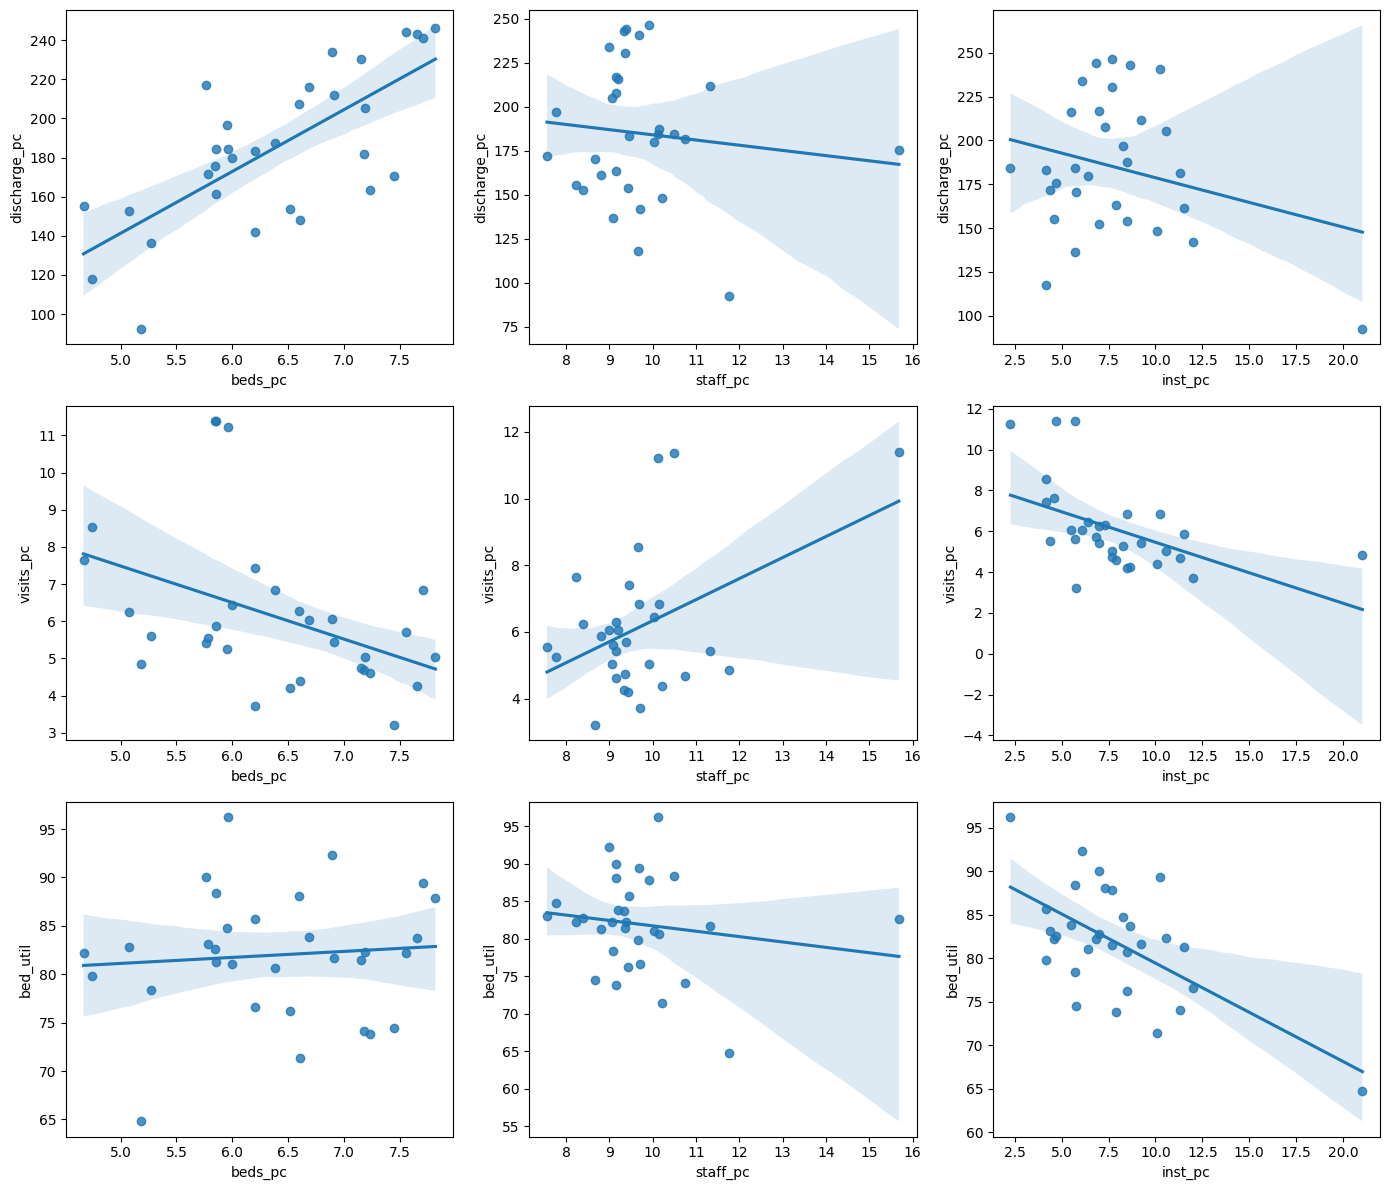

In [13]:
X = ["beds_pc","staff_pc","inst_pc"]
Y = ["discharge_pc","visits_pc","bed_util"]

fig, axes = plt.subplots(3, 3, figsize=(14,12))
for i, y in enumerate(Y):
    for j, x in enumerate(X):
        sns.regplot(data=d19, x=x, y=y, ax=axes[i][j])
plt.tight_layout()
plt.show()

In [14]:
m = smf.ols("discharge_pc ~ beds_pc + staff_pc + inst_pc", data=d19).fit()
print(m.summary())

                            OLS Regression Results                            
Dep. Variable:           discharge_pc   R-squared:                       0.633
Model:                            OLS   Adj. R-squared:                  0.592
Method:                 Least Squares   F-statistic:                     15.52
Date:                Sat, 10 Oct 2026   Prob (F-statistic):           4.60e-06
Time:                        21:04:57   Log-Likelihood:                -141.33
No. Observations:                  31   AIC:                             290.7
Df Residuals:                      27   BIC:                             296.4
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     13.6187     44.994      0.303      0.7

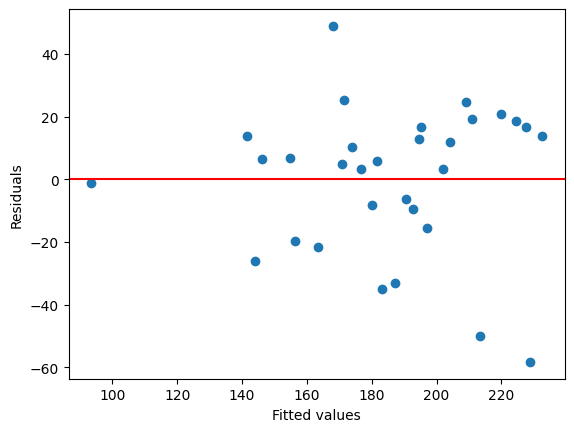

In [15]:
plt.scatter(m.fittedvalues, m.resid)
plt.axhline(0, color="red")
plt.xlabel("Fitted values"); plt.ylabel("Residuals")
plt.show()

In [16]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
Xv = d19[["beds_pc","staff_pc","inst_pc"]].assign(const=1)
for i, c in enumerate(Xv.columns[:-1]):
    print(c, round(variance_inflation_factor(Xv.values, i), 2))

beds_pc 1.01
staff_pc 1.03
inst_pc 1.05


In [17]:
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import OLSInfluence

# robust SEs
print(m.get_robustcov_results("HC3").summary())
# heteroskedasticity test
print(het_breuschpagan(m.resid, m.model.exog))
# influential points
cd = OLSInfluence(m).cooks_distance[0]
print(d19.assign(cooks=cd).sort_values("cooks", ascending=False)[["Province","cooks"]].head())
# drop Xizang
m2 = smf.ols("discharge_pc ~ beds_pc + staff_pc + inst_pc", d19[d19.Province!="Xizang"]).fit()
print(m2.summary())
# repeat for 2023
m3 = smf.ols("discharge_pc ~ beds_pc + staff_pc + inst_pc", d23).fit()
print(m3.summary())

                            OLS Regression Results                            
Dep. Variable:           discharge_pc   R-squared:                       0.633
Model:                            OLS   Adj. R-squared:                  0.592
Method:                 Least Squares   F-statistic:                     18.53
Date:                Sat, 10 Oct 2026   Prob (F-statistic):           9.89e-07
Time:                        21:04:57   Log-Likelihood:                -141.33
No. Observations:                  31   AIC:                             290.7
Df Residuals:                      27   BIC:                             296.4
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     13.6187     37.751      0.361      0.7